In [88]:
import sys
from pathlib import Path

project_root = Path.cwd().parent.parent.parent
sys.path.insert(0, str(project_root))

In [89]:
from pathlib import Path

import matplotlib.pyplot as plt

%matplotlib inline

from tools.cell_characterisation.common import plot_measurements, read_measurements
from tools.cell_characterisation.pocv_to_ocv_vhyst import build_ocv_lut, calc_ocv

In [ ]:
TL = 1
TR = 10

In [91]:
DATA = [Path(r"./data/124_02_pOCV_C100_LFP_Haidi_YF047.txt")]

In [92]:
meas = read_measurements(DATA)

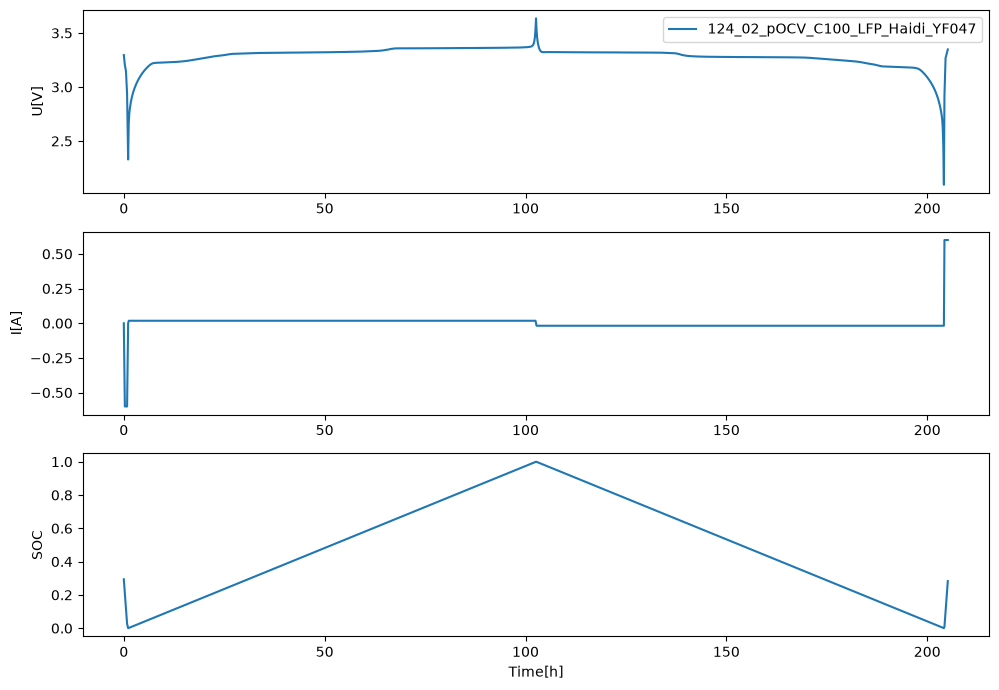

In [93]:
plot_measurements(meas, slice_step=100)

In [94]:
meas['124_02_pOCV_C100_LFP_Haidi_YF047'][1000:2000]

,~Time[s],DataSet,t-Step[s],Line,Command,U[V],I[A],Ah[Ah],Ah-Step,T1[°C],Cyc-Count,State,SOC
1000,6905.588174,1001,2950.535970,11,Charge,2.891975,0.018,-0.521961,0.014753,25.63830,1,1,0.008147
1001,6910.594069,1002,2955.541865,11,Charge,2.892165,0.018,-0.521936,0.014778,25.67173,1,1,0.008161
1002,6915.588454,1003,2960.536251,11,Charge,2.892547,0.018,-0.521911,0.014803,25.65350,1,1,0.008175
1003,6920.594929,1004,2965.542725,11,Charge,2.892737,0.018,-0.521886,0.014828,25.58967,1,1,0.008188
1004,6925.595301,1005,2970.543098,11,Charge,2.892928,0.018,-0.521861,0.014853,25.57751,1,1,0.008202
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,11881.251993,1996,7926.199789,11,Charge,3.044876,0.018,-0.497083,0.039631,25.67477,1,1,0.021765
1996,11886.251933,1997,7931.199729,11,Charge,3.045067,0.018,-0.497058,0.039656,25.61094,1,1,0.021778
1997,11891.252351,1998,7936.200148,11,Charge,3.045067,0.018,-0.497033,0.039681,25.58359,1,1,0.021792
1998,11896.252764,1999,7941.200560,11,Charge,3.045258,0.018,-0.497008,0.039706,25.59574,1,1,0.021806


In [95]:
charge_df, discharge_df = calc_ocv(meas)
lut = build_ocv_lut(charge_df, discharge_df, trunc_L=TL, trunc_R=TR)
lut = lut["124_02_pOCV_C100_LFP_Haidi_YF047"]
lut

,SOC,OCV[V],Vhyst[V]
0,0.00,2.181707,0.047819
1,0.01,2.873775,0.047819
2,0.02,2.989880,0.040519
3,0.03,3.064609,0.037081
4,0.04,3.119090,0.034729
...,...,...,...
96,0.96,3.344388,0.020590
97,0.97,3.345055,0.020590
98,0.98,3.346008,0.020590
99,0.99,3.356693,0.020590


In [96]:
charge_df

,SOC,U[V],File
0,0.000073,2.364445,124_02_pOCV_C100_LFP_Haidi_YF047
1,0.000073,2.365017,124_02_pOCV_C100_LFP_Haidi_YF047
2,0.000086,2.378935,124_02_pOCV_C100_LFP_Haidi_YF047
3,0.000100,2.386942,124_02_pOCV_C100_LFP_Haidi_YF047
4,0.000114,2.393424,124_02_pOCV_C100_LFP_Haidi_YF047
...,...,...,...
73065,0.999961,3.644662,124_02_pOCV_C100_LFP_Haidi_YF047
73066,0.999975,3.646950,124_02_pOCV_C100_LFP_Haidi_YF047
73067,0.999989,3.649047,124_02_pOCV_C100_LFP_Haidi_YF047
73068,0.999997,3.650572,124_02_pOCV_C100_LFP_Haidi_YF047


In [97]:
discharge_df

,SOC,U[V],File
0,1.000000,3.620450,124_02_pOCV_C100_LFP_Haidi_YF047
1,1.000000,3.619687,124_02_pOCV_C100_LFP_Haidi_YF047
2,0.999986,3.616065,124_02_pOCV_C100_LFP_Haidi_YF047
3,0.999973,3.612633,124_02_pOCV_C100_LFP_Haidi_YF047
4,0.999959,3.609392,124_02_pOCV_C100_LFP_Haidi_YF047
...,...,...,...
73074,0.000042,2.011552,124_02_pOCV_C100_LFP_Haidi_YF047
73075,0.000028,2.007167,124_02_pOCV_C100_LFP_Haidi_YF047
73076,0.000015,2.002972,124_02_pOCV_C100_LFP_Haidi_YF047
73077,0.000002,1.998969,124_02_pOCV_C100_LFP_Haidi_YF047


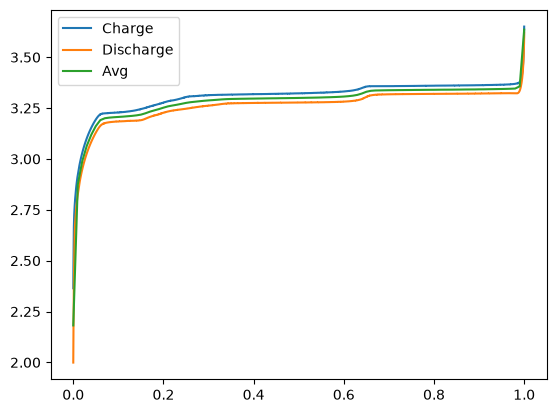

In [98]:
plt.plot(charge_df["SOC"], charge_df["U[V]"], label="Charge")
plt.plot(discharge_df["SOC"], discharge_df["U[V]"], label="Discharge")
plt.plot(lut["SOC"], lut["OCV[V]"], label="Avg")
plt.legend()

<Axes: xlabel='SOC'>

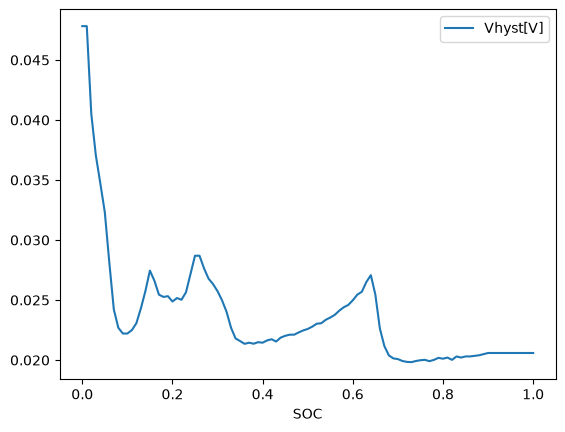

In [99]:
lut.plot("SOC", "Vhyst[V]")

In [100]:
DATA_DIR = Path(r"./data")
DATA = sorted(DATA_DIR.glob("*pOCV*LiWerks*.txt"))

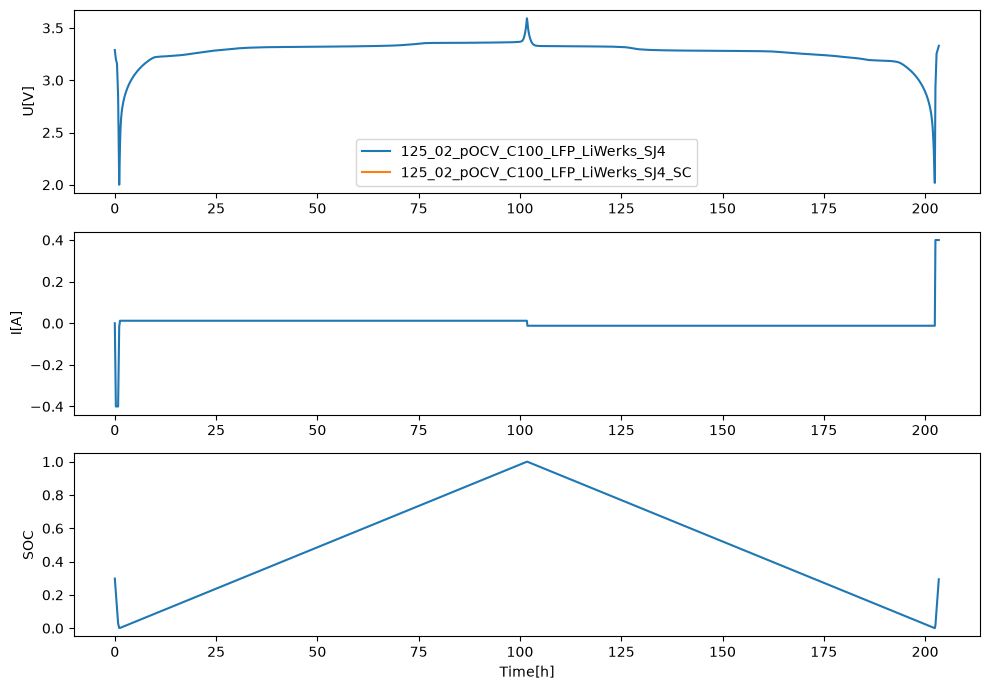

In [101]:
meas = read_measurements(DATA)
plot_measurements(meas, slice_step=100)
charge_df, discharge_df = calc_ocv(meas)
lut = build_ocv_lut(charge_df, discharge_df, trunc_L=TL, trunc_R=TR)
lut = lut["125_02_pOCV_C100_LFP_LiWerks_SJ4"]

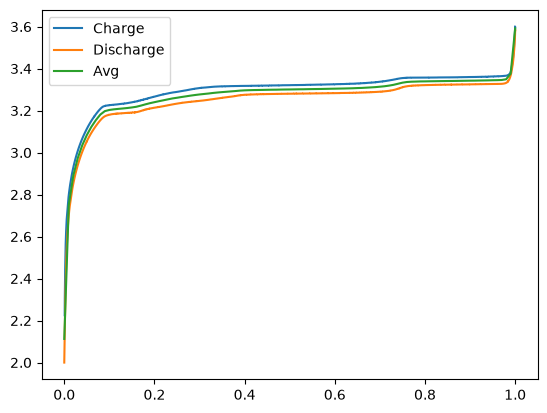

In [102]:
plt.plot(charge_df["SOC"], charge_df["U[V]"], label="Charge")
plt.plot(discharge_df["SOC"], discharge_df["U[V]"], label="Discharge")
plt.plot(lut["SOC"], lut["OCV[V]"], label="Avg")
plt.legend()

<Axes: xlabel='SOC'>

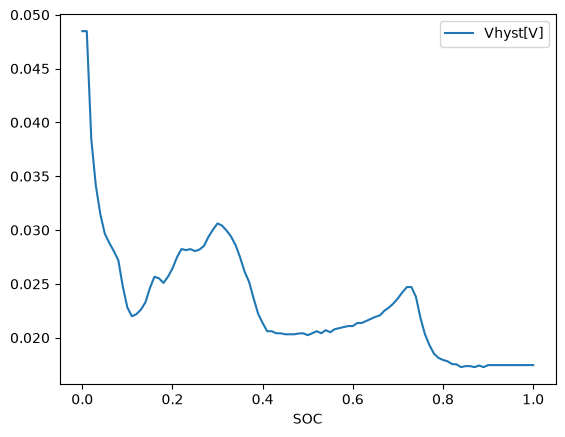

In [103]:
lut.plot("SOC", "Vhyst[V]")

In [104]:
charge_df

,SOC,U[V],File
0,0.000948,2.225184,125_02_pOCV_C100_LFP_LiWerks_SJ4
1,0.000948,2.225375,125_02_pOCV_C100_LFP_LiWerks_SJ4
2,0.000961,2.233387,125_02_pOCV_C100_LFP_LiWerks_SJ4
3,0.000975,2.239683,125_02_pOCV_C100_LFP_LiWerks_SJ4
4,0.000989,2.245406,125_02_pOCV_C100_LFP_LiWerks_SJ4
...,...,...,...
72358,0.999974,3.599136,125_02_pOCV_C100_LFP_LiWerks_SJ4
72359,0.999988,3.599899,125_02_pOCV_C100_LFP_LiWerks_SJ4
72360,0.999997,3.600281,125_02_pOCV_C100_LFP_LiWerks_SJ4
72361,0.999997,3.600281,125_02_pOCV_C100_LFP_LiWerks_SJ4


In [105]:
discharge_df

,SOC,U[V],File
0,1.000000,3.583111,125_02_pOCV_C100_LFP_LiWerks_SJ4
1,1.000000,3.583111,125_02_pOCV_C100_LFP_LiWerks_SJ4
2,0.999986,3.581394,125_02_pOCV_C100_LFP_LiWerks_SJ4
3,0.999972,3.580059,125_02_pOCV_C100_LFP_LiWerks_SJ4
4,0.999959,3.578533,125_02_pOCV_C100_LFP_LiWerks_SJ4
...,...,...,...
72431,0.000019,2.001597,125_02_pOCV_C100_LFP_LiWerks_SJ4
72432,0.000005,2.000071,125_02_pOCV_C100_LFP_LiWerks_SJ4
72433,0.000002,1.999690,125_02_pOCV_C100_LFP_LiWerks_SJ4
72434,0.000002,1.999690,125_02_pOCV_C100_LFP_LiWerks_SJ4


In [106]:
lut

,SOC,OCV[V],Vhyst[V]
0,0.00,2.112437,0.048477
1,0.01,2.750017,0.048477
2,0.02,2.890126,0.038441
3,0.03,2.974359,0.034155
4,0.04,3.035591,0.031478
...,...,...,...
96,0.96,3.345121,0.017456
97,0.97,3.345888,0.017456
98,0.98,3.349318,0.017456
99,0.99,3.376246,0.017456
